<a href="https://colab.research.google.com/github/bdipesh3045/Data-Science-project-AI-Class-/blob/main/palden/main1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
%pip install -q kagglehub scikit-learn matplotlib

import os, glob, time
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import kagglehub

from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

In [14]:
path = kagglehub.dataset_download("datamunge/sign-language-mnist")

train_csv = glob.glob(os.path.join(path, "**", "sign_mnist_train.csv"), recursive=True)[0]
test_csv  = glob.glob(os.path.join(path, "**", "sign_mnist_test.csv"),  recursive=True)[0]

train_df = pd.read_csv(train_csv)
test_df  = pd.read_csv(test_csv)
print("Train:", train_df.shape, "| Test:", test_df.shape)   # (27455, 785) | (7172, 785)

Using Colab cache for faster access to the 'sign-language-mnist' dataset.
Train: (27455, 785) | Test: (7172, 785)


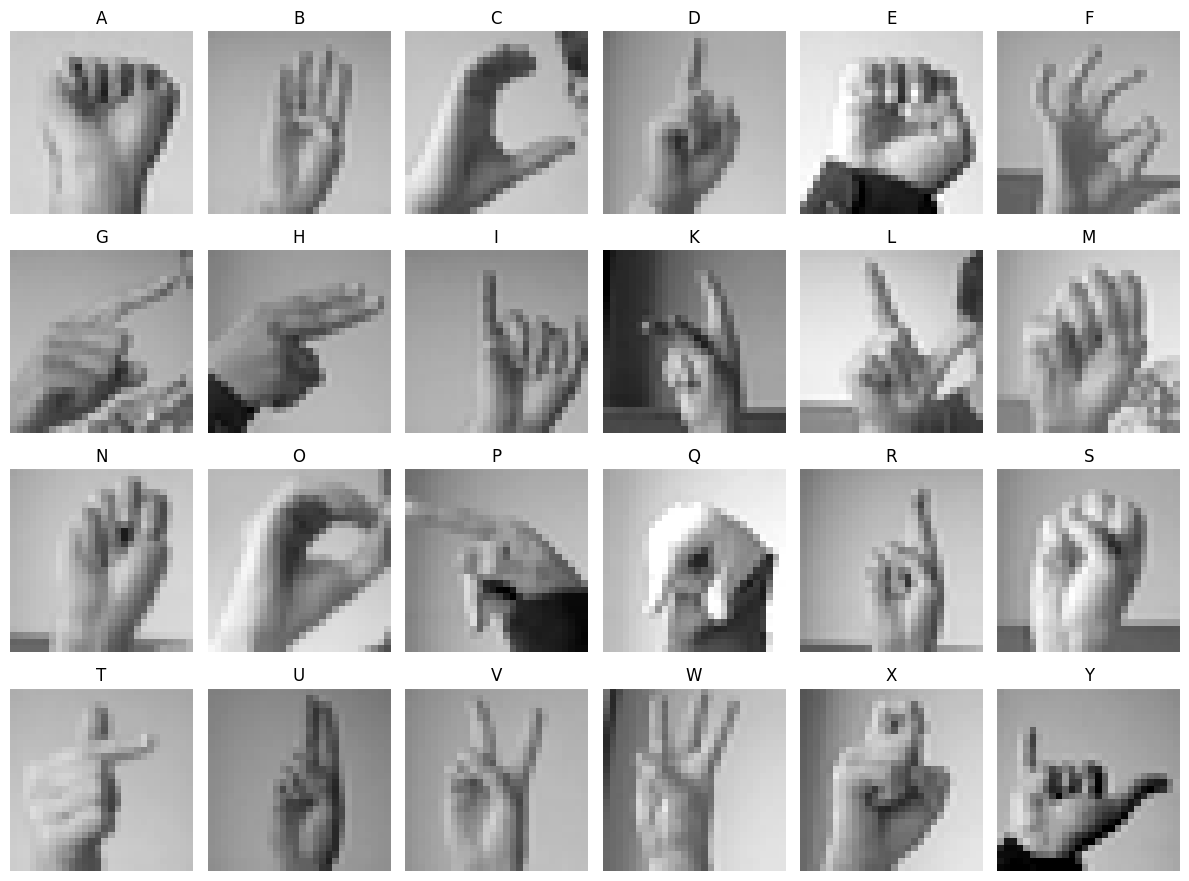

In [15]:
labels  = sorted(train_df["label"].unique())     # 24 classes (no J=9, no Z=25)
letters = [chr(65 + int(l)) for l in labels]

plt.figure(figsize=(12, 9))
for i, label in enumerate(labels):
    row = train_df[train_df["label"] == label].iloc[0]
    plt.subplot(4, 6, i + 1)
    plt.imshow(row.drop("label").to_numpy().reshape(28, 28), cmap="gray", vmin=0, vmax=255)
    plt.title(letters[i])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [16]:
# Train on the full train CSV, evaluate on the separate test CSV.
# (Splitting the train CSV leaks near-duplicate augmented images -> fake ~100%.)
X_train = train_df.drop(columns="label").to_numpy(dtype="float32") / 255.0
y_train = train_df["label"].to_numpy()
X_test  = test_df.drop(columns="label").to_numpy(dtype="float32") / 255.0
y_test  = test_df["label"].to_numpy()

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (27455, 784) | X_test: (7172, 784)


In [17]:
svm = SVC(kernel="rbf", C=10, gamma="scale")

start = time.time()
svm.fit(X_train, y_train)
print(f"Training time: {time.time() - start:.1f} s")

Training time: 104.8 s


In [12]:
y_pred = svm.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1  = f1_score(y_test, y_pred, average="macro")
print(f"Test accuracy: {acc:.2%}")
print(f"Macro F1:      {f1:.4f}")

Test accuracy: 83.71%
Macro F1:      0.8203


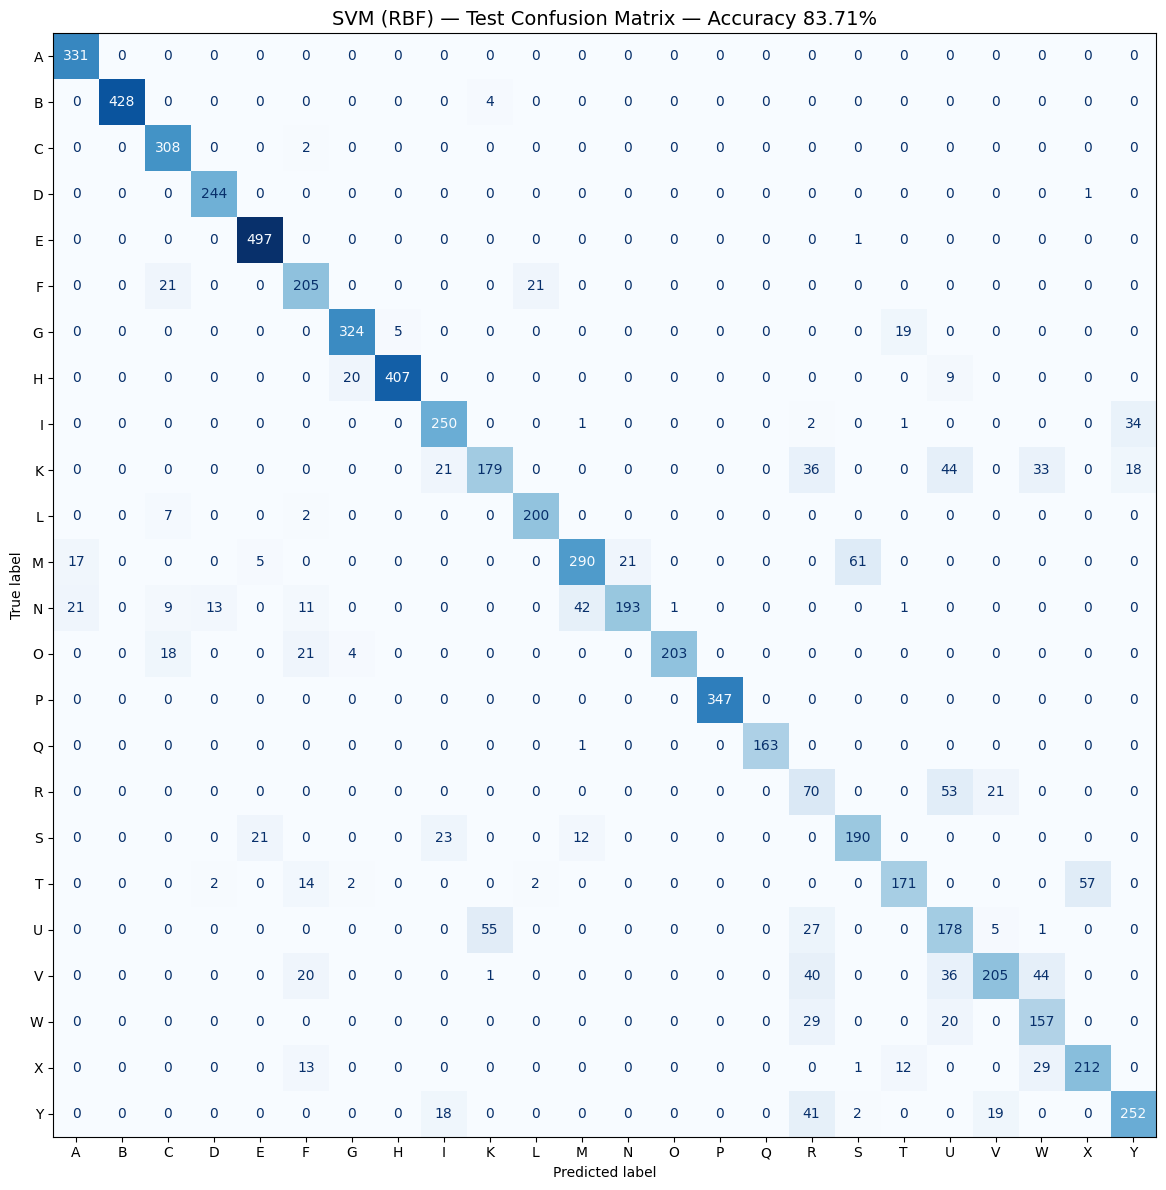

In [18]:
fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=labels,
    display_labels=letters,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"SVM (RBF) — Test Confusion Matrix — Accuracy {acc:.2%}", fontsize=14)
plt.tight_layout()
plt.savefig("svm_confusion_matrix.png", dpi=150)
plt.show()